In [1]:
## %% [markdown]
# # 03. PCA композиционного пространства и пул незаполненных областей
# Проект: Fe-Ni-Co-Al-Cr-Ti alloy composition space

# %%
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

from src.alloy_space.descriptors import calculate_descriptors

FIGURES_DIR = BASE_DIR / "outputs" / "figures"
TABLES_DIR = BASE_DIR / "outputs" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", font_scale=1.05)
plt.rcParams['figure.dpi'] = 120

# %%
# 1. Загрузка данных
df_comp = pd.read_parquet(BASE_DIR / "data" / "processed" / "dataset_compositions_unique.parquet")
BASE_6 = ['Ni', 'Co', 'Fe', 'Cr', 'Al', 'Ti']
assert set(BASE_6) <= set(df_comp.columns), "Нет колонок базовых элементов"

N_ALLOYS = len(df_comp)
X_base6 = df_comp[BASE_6].values
X_base6 = X_base6 / X_base6.sum(axis=1, keepdims=True) * 100.0

# Al+Ti и Al/Ti для литературных составов (для рис. 08 и текста про окно)
df_comp['Al_plus_Ti'] = df_comp['Al'] + df_comp['Ti']
df_comp['Al_to_Ti_ratio'] = df_comp['Al'] / df_comp['Ti'].replace(0, np.nan)

cols = ['Al_plus_Ti', 'Al_to_Ti_ratio']
print(f"Литературных составов: {N_ALLOYS}")
print("Все составы:")
print(df_comp[cols].describe(percentiles=[.05, .5, .95]).round(2).to_string())
print("\nСоставы с Target state = 1:")
print(df_comp.loc[df_comp['Target state'] == 1, cols]
      .describe(percentiles=[.05, .5, .95]).round(2).to_string())

Литературных составов: 161
Все составы:
       Al_plus_Ti  Al_to_Ti_ratio
count      161.00          116.00
mean        10.71            1.67
std          5.63            1.27
min          0.00            0.00
5%           4.00            0.23
50%          9.10            1.35
95%         17.30            3.29
max         40.00            8.00

Составы с Target state = 1:
       Al_plus_Ti  Al_to_Ti_ratio
count       87.00           77.00
mean        10.57            1.69
std          3.71            1.33
min          2.70            0.00
5%           6.00            0.50
50%          9.20            1.38
95%         16.10            3.03
max         18.10            8.00


In [2]:
# %%
# 2. PCA на стандартизованных концентрациях базовых элементов
scaler_base6 = StandardScaler()
X_base6_scaled = scaler_base6.fit_transform(X_base6)

pca = PCA(n_components=len(BASE_6))
X_pca_full = pca.fit_transform(X_base6_scaled)

for i in range(3):
    df_comp[f'PC{i + 1}'] = X_pca_full[:, i]

exp_var = pca.explained_variance_ratio_ * 100
variance_table = pd.DataFrame({
    'Component': [f'PC{i + 1}' for i in range(len(exp_var))],
    'Explained variance, %': exp_var.round(2),
    'Cumulative, %': np.cumsum(exp_var).round(2)})
print(variance_table.to_string(index=False))

loadings = pd.DataFrame(pca.components_[:3].T, columns=['PC1', 'PC2', 'PC3'], index=BASE_6)
print("\n=== Нагрузки элементов на PC1–PC3 ===")
print(loadings.round(3))
print("\n=== Вклад элемента в дисперсию оси, % ===")
print(((loadings ** 2) * 100).round(1))

with pd.ExcelWriter(TABLES_DIR / "pca_summary.xlsx", engine="openpyxl") as writer:
    variance_table.to_excel(writer, sheet_name="Explained_variance", index=False)
    loadings.round(4).rename_axis("Element").reset_index().to_excel(
        writer, sheet_name="Loadings_PC1-3", index=False)

Component  Explained variance, %  Cumulative, %
      PC1                  28.80          28.80
      PC2                  23.62          52.42
      PC3                  18.62          71.04
      PC4                  16.18          87.21
      PC5                  12.79         100.00
      PC6                   0.00         100.00

=== Нагрузки элементов на PC1–PC3 ===
      PC1    PC2    PC3
Ni  0.663 -0.091  0.003
Co -0.518 -0.568 -0.186
Fe -0.234  0.643 -0.351
Cr -0.139  0.190  0.899
Al  0.282  0.286 -0.186
Ti  0.372 -0.370 -0.008

=== Вклад элемента в дисперсию оси, % ===
     PC1   PC2   PC3
Ni  44.0   0.8   0.0
Co  26.8  32.2   3.5
Fe   5.5  41.4  12.3
Cr   1.9   3.6  80.8
Al   7.9   8.2   3.4
Ti  13.8  13.7   0.0


In [3]:
# %%
# 3. 3D-сетка, возврат в состав, L1_2-окно, пул
MARGIN, GRID_N = 0.15, 35
pcs = df_comp[['PC1', 'PC2', 'PC3']].values

axes_1d = [np.linspace(pcs[:, k].min() - MARGIN * np.ptp(pcs[:, k]),
                       pcs[:, k].max() + MARGIN * np.ptp(pcs[:, k]), GRID_N) for k in range(3)]
grid = np.column_stack([g.ravel() for g in np.meshgrid(*axes_1d)])

nn = NearestNeighbors(n_neighbors=1).fit(pcs)
df_grid = pd.DataFrame(grid, columns=['PC1', 'PC2', 'PC3'])
df_grid['dist_to_nearest_alloy'] = nn.kneighbors(grid)[0].ravel()

full = np.zeros((len(grid), pca.n_components_))
full[:, :3] = grid
comp = pd.DataFrame(scaler_base6.inverse_transform(pca.inverse_transform(full)), columns=BASE_6)
df_grid = pd.concat([df_grid, comp], axis=1)

df_valid = df_grid[(df_grid[BASE_6] >= -1.0).all(axis=1)].copy()
df_valid[BASE_6] = df_valid[BASE_6].clip(lower=0)
df_valid[BASE_6] = df_valid[BASE_6].div(df_valid[BASE_6].sum(axis=1), axis=0) * 100.0
df_valid = pd.concat([df_valid, calculate_descriptors(df_valid)], axis=1)

def in_l12_window(d):
    return ((d['VEC'] >= 7.85)
            & d['Al_plus_Ti'].between(8.0, 12.5)
            & d['Al_to_Ti_ratio'].between(0.9, 2.2)
            & (d['delta_atomic_radius'] <= 6.0))

valid_l12 = df_valid[in_l12_window(df_valid)].copy()
gap_threshold = float(np.percentile(valid_l12['dist_to_nearest_alloy'], 85))
gap_pool = valid_l12[valid_l12['dist_to_nearest_alloy'] >= gap_threshold].copy()

print(f"Узлов сетки: {len(df_grid)}; физически валидных: {len(df_valid)}; "
      f"в L1_2-окне: {len(valid_l12)}; порог 85-го перцентиля: {gap_threshold:.3f}; пул: {len(gap_pool)}")
pool_cols = BASE_6 + ['VEC', 'Al_plus_Ti', 'Al_to_Ti_ratio', 'delta_atomic_radius', 'dist_to_nearest_alloy']
gap_pool[pool_cols].round(2).to_excel(TABLES_DIR / "pca3d_gap_pool_base6.xlsx", index=False)

Узлов сетки: 42875; физически валидных: 12505; в L1_2-окне: 840; порог 85-го перцентиля: 0.850; пул: 126


In [4]:
# %%
# 4. Кандидаты (выбраны вручную по интерактивному 3D-графику) и выплавленные образцы
CANDIDATES = pd.DataFrame([
    [38.72, 29.72,  4.76, 14.88, 5.69, 6.24],   # 1
    [33.66, 23.78,  5.91, 27.30, 5.02, 4.33],   # 2
    [37.55, 20.18,  0.60, 31.72, 4.88, 5.07],   # 3
    [41.00, 15.44,  5.10, 26.29, 6.85, 5.32],   # 4
    [28.97, 22.47, 12.80, 27.40, 5.52, 2.84],   # 5
    [32.66, 36.37, 16.05,  3.29, 6.52, 5.12],   # 6
    [26.29, 40.56, 20.55,  2.88, 5.88, 3.84],   # 7
    [26.83, 42.40, 14.95,  6.82, 4.70, 4.31],   # 8
    [25.17, 48.38, 16.64,  0.89, 4.45, 4.47],   # 9
    [22.18, 45.42, 23.38,  0.41, 5.37, 3.24],   # 10
    [41.92, 21.55,  1.44, 22.80, 6.01, 6.28],   # 11
    [41.41, 17.89,  0.62, 28.42, 5.87, 5.79],   # 12
], columns=BASE_6)
CANDIDATES.insert(0, 'Alloy_Number', range(1, len(CANDIDATES) + 1))
CANDIDATES['Cluster'] = ['Upper'] * 5 + ['Lower'] * 5 + ['Upper'] * 2   # 11-12: проверьте

def project(comp_df):
    X = comp_df[BASE_6].values.astype(float)
    X = X / X.sum(axis=1, keepdims=True) * 100.0
    z = pca.transform(scaler_base6.transform(X))
    out = comp_df.copy()
    out[['PC1', 'PC2', 'PC3']] = z[:, :3]
    return out

cand = project(CANDIDATES)
cand = pd.concat([cand, calculate_descriptors(cand)], axis=1)
cand['in_L12_window'] = in_l12_window(cand)
cand['dist_to_nearest_alloy'] = nn.kneighbors(cand[['PC1', 'PC2', 'PC3']].values)[0].ravel()
cand['beyond_gap_threshold'] = cand['dist_to_nearest_alloy'] >= gap_threshold
print("Суммы составов кандидатов:", CANDIDATES[BASE_6].sum(axis=1).round(2).tolist())
print(cand[['Alloy_Number', 'Cluster', 'Al_plus_Ti', 'Al_to_Ti_ratio', 'VEC',
            'in_L12_window', 'dist_to_nearest_alloy', 'beyond_gap_threshold']].round(2).to_string(index=False))
cand.round(3).to_excel(TABLES_DIR / "candidates_12.xlsx", index=False)

melting_raw = pd.read_excel(BASE_DIR / "data" / "raw" / "HEA_melting_results.xlsx")
melting_raw.columns = [c.strip() for c in melting_raw.columns]
assert set(BASE_6) <= set(melting_raw.columns), "В файле выплавок нет колонок базовых элементов"
melted = project(melting_raw[BASE_6].astype(float))
melted['Alloy_Number'] = range(13, 13 + len(melted))
other_cols = [c for c in melting_raw.columns if c not in BASE_6]
if other_cols:
    melted[other_cols] = melting_raw[other_cols].values
print("Суммы составов выплавок:", melted[BASE_6].sum(axis=1).round(2).tolist())

Суммы составов кандидатов: [100.01, 100.0, 100.0, 100.0, 100.0, 100.01, 100.0, 100.01, 100.0, 100.0, 100.0, 100.0]
 Alloy_Number Cluster  Al_plus_Ti  Al_to_Ti_ratio  VEC  in_L12_window  dist_to_nearest_alloy  beyond_gap_threshold
            1   Upper       11.93            0.91 8.24           True                   1.01                  True
            2   Upper        9.35            1.16 7.94           True                   0.91                  True
            3   Upper        9.95            0.96 7.87           True                   1.22                  True
            4   Upper       12.17            1.29 7.89           True                   0.61                 False
            5   Upper        8.36            1.94 7.87           True                   0.89                  True
            6   Lower       11.64            1.27 8.42           True                   0.90                  True
            7   Lower        9.72            1.53 8.43           True           

In [5]:
# %%
# 5. Итоговый график
import plotly.graph_objects as go

LABELS = {'lit': 'Literature alloys', 'pool': 'Gap pool (hidden by default)',
          'cand': 'Candidate alloys', 'melt': 'Melted samples'}
CAMERA = dict(eye=dict(x=1.6, y=1.6, z=0.9))

def fmt(v):
    return f"{v:.2f}" if isinstance(v, (float, np.floating)) else str(v)

def hover_text(df, prefix=None, extra=()):
    out = []
    for i, (_, r) in enumerate(df.iterrows()):
        head = f"<b>{prefix[i]}</b><br>" if prefix is not None else ""
        comps = ", ".join(f"{c}={r[c]:.1f}" for c in BASE_6)
        tail = "".join(f"<br>{c}={fmt(r[c])}" for c in extra)
        out.append(head + comps + tail)
    return out

# %%
# Связи между кандидатами верхнего кластера (бывшие жёлтые + бывшие бирюзовые)
UPPER_LINKS = [
    (5, 4), (5, 2), (5, 3), (3, 4), (3, 2), (1, 4), (1, 2),            # были жёлтыми
    (12, 2), (12, 3), (12, 4), (12, 11), (11, 1), (11, 2), (11, 4),    # были бирюзовыми
]
LOWER_LINKS = [(10, 7), (10, 9), (10, 8), (8, 7), (8, 9), (6, 8), (6, 9), (6, 7)]   # нижний кластер настроим позже
LINKS = sorted({tuple(sorted(p)) for p in UPPER_LINKS + LOWER_LINKS})
LINK_COLOR = 'goldenrod'

points_by_number = {int(r.Alloy_Number): (r.PC1, r.PC2, r.PC3) for r in cand.itertuples()}
assert all(a in points_by_number and b in points_by_number for a, b in LINKS), "Связь на несуществующий номер"

def links_trace(pairs, color=LINK_COLOR, name='Links between candidates', width=4):
    xs, ys, zs = [], [], []
    for a, b in pairs:
        pa, pb = points_by_number[a], points_by_number[b]
        xs += [pa[0], pb[0], None]
        ys += [pa[1], pb[1], None]
        zs += [pa[2], pb[2], None]
    return go.Scatter3d(x=xs, y=ys, z=zs, mode='lines',
                        line=dict(color=color, width=width),
                        name=name, hoverinfo='skip')

def make_figure(show_pool=False, show_window=False, links=None, width=1000, height=750):
    fig = go.Figure()
    fig.add_trace(go.Scatter3d(
        x=df_comp['PC1'], y=df_comp['PC2'], z=df_comp['PC3'], mode='markers',
        marker=dict(size=5, color='steelblue', opacity=0.7, line=dict(width=0.5, color='black')),
        name=f"{LABELS['lit']} (n={len(df_comp)})",
        text=hover_text(df_comp), hoverinfo='text'))
    if show_window:
        fig.add_trace(go.Scatter3d(
        x=valid_l12['PC1'], y=valid_l12['PC2'], z=valid_l12['PC3'], mode='markers',
        marker=dict(size=3, color=valid_l12['dist_to_nearest_alloy'], colorscale='Viridis',
                    cmin=0, cmax=valid_l12['dist_to_nearest_alloy'].max(),
                    opacity=0.5, showscale=True,
                    colorbar=dict(title='dist to nearest<br>literature alloy', len=0.6)),
        name=f"L1₂-window nodes (n={len(valid_l12)})",
        text=hover_text(valid_l12, extra=['Al_plus_Ti', 'Al_to_Ti_ratio', 'VEC',
                                          'delta_atomic_radius', 'dist_to_nearest_alloy']),
        hoverinfo='text'))
    if show_pool:
        fig.add_trace(go.Scatter3d(
            x=gap_pool['PC1'], y=gap_pool['PC2'], z=gap_pool['PC3'], mode='markers',
            marker=dict(size=5, color='gray', opacity=0.6, symbol='circle-open', line=dict(width=1, color='gray')),
            name=f"{LABELS['pool']} (n={len(gap_pool)})",
            text=hover_text(gap_pool, extra=['dist_to_nearest_alloy']),
            hoverinfo='text', visible=True))
    fig.add_trace(go.Scatter3d(
        x=cand['PC1'], y=cand['PC2'], z=cand['PC3'], mode='markers+text',
        marker=dict(size=9, color='gold', symbol='diamond', line=dict(width=2, color='black')),
        text=cand['Alloy_Number'].astype(str), textposition='top center',
        textfont=dict(size=13, color='black'),
        hovertext=hover_text(cand, prefix=[f"Candidate {n}" for n in cand['Alloy_Number']],
                             extra=['Cluster', 'dist_to_nearest_alloy']),
        hoverinfo='text', name=f"{LABELS['cand']} (n={len(cand)})"))
    fig.add_trace(go.Scatter3d(
        x=melted['PC1'], y=melted['PC2'], z=melted['PC3'], mode='markers+text',
        marker=dict(size=11, color='limegreen', symbol='square', line=dict(width=2, color='black')),
        text=melted['Alloy_Number'].astype(str), textposition='top center',
        textfont=dict(size=13, color='darkgreen'),
        hovertext=hover_text(melted, prefix=[f"Sample {n}" for n in melted['Alloy_Number']],
                             extra=other_cols),
        hoverinfo='text', name=f"{LABELS['melt']} (n={len(melted)})"))
    if links:
        fig.add_trace(links_trace(links))
    fig.update_layout(
        template='plotly_white', width=width, height=height,
        legend=dict(itemsizing='constant'),
        scene=dict(xaxis_title=f"PC1 ({exp_var[0]:.1f}%)",
                   yaxis_title=f"PC2 ({exp_var[1]:.1f}%)",
                   zaxis_title=f"PC3 ({exp_var[2]:.1f}%)",
                   camera=CAMERA))
    return fig


make_figure(show_pool=True, show_window=True, links=LINKS).write_html(
    str(FIGURES_DIR / "pca3d_composition_space_2.html"))

fig_static = make_figure(show_pool=True, show_window=True, links=LINKS)
fig_static.show()

In [6]:
def window_margin(d):
    m = pd.DataFrame({
        'Al+Ti': np.minimum(d['Al_plus_Ti'] - 8.0, 12.5 - d['Al_plus_Ti']),
        'Al/Ti': np.minimum(d['Al_to_Ti_ratio'] - 0.9, 2.2 - d['Al_to_Ti_ratio']),
        'VEC':   d['VEC'] - 7.85,
        'delta': 6.0 - d['delta_atomic_radius']}, index=d.index)
    return m

cand_margin = window_margin(cand)
cand['nearest_face'] = cand_margin.idxmin(axis=1)
print(cand[['Alloy_Number', 'nearest_face']].join(cand_margin.round(3)))

    Alloy_Number nearest_face  Al+Ti  Al/Ti    VEC  delta
0              1        Al/Ti   0.57  0.012  0.390  0.897
1              2          VEC   1.35  0.259  0.091  1.435
2              3          VEC   1.95  0.063  0.022  1.287
3              4          VEC   0.33  0.388  0.043  0.903
4              5          VEC   0.36  0.256  0.017  1.720
5              6        Al/Ti   0.86  0.373  0.570  0.990
6              7          VEC   1.72  0.631  0.576  1.386
7              8        Al/Ti   1.01  0.190  0.567  1.494
8              9        Al/Ti   0.92  0.096  0.718  1.500
9             10        Al/Ti   0.61  0.543  0.642  1.635
10            11        Al/Ti   0.21  0.057  0.196  0.842
11            12          VEC   0.84  0.114  0.064  0.963


In [7]:
def near_face(d, tol=dict(AlTi=0.6, ratio=0.12, VEC=0.1, delta=0.5)):
    m = window_margin(d)
    return ((m['Al+Ti'] < tol['AlTi']) | (m['Al/Ti'] < tol['ratio'])
            | (m['VEC'] < tol['VEC']) | (m['delta'] < tol['delta']))

print("Окно, доля у граней:", near_face(valid_l12).mean().round(2))
print("Пул, доля у граней: ", near_face(gap_pool).mean().round(2))
print("Кандидаты:          ", near_face(cand).mean().round(2))
print("Расстояния в пуле: max =", gap_pool['dist_to_nearest_alloy'].max().round(3))
print(cand[['Alloy_Number', 'dist_to_nearest_alloy']].assign(
    pct_in_pool=lambda t: [(gap_pool['dist_to_nearest_alloy'] <= v).mean().round(2)
                           for v in t['dist_to_nearest_alloy']]))

Окно, доля у граней: 0.51
Пул, доля у граней:  0.6
Кандидаты:           0.67
Расстояния в пуле: max = 1.22
    Alloy_Number  dist_to_nearest_alloy  pct_in_pool
0              1               1.005991         0.69
1              2               0.914896         0.32
2              3               1.217939         0.99
3              4               0.612971         0.00
4              5               0.885167         0.19
5              6               0.898978         0.25
6              7               0.903498         0.28
7              8               0.963930         0.50
8              9               0.955716         0.50
9             10               1.148172         0.94
10            11               0.856972         0.05
11            12               1.074170         0.86


       removed by criterion  removed ONLY by it  share of valid, %
Al+Ti                  8835                1987               70.7
Al/Ti                  8330                1644               66.6
VEC                    2815                 295               22.5
delta                   706                   0                5.6
Passed all: 840 of 12505


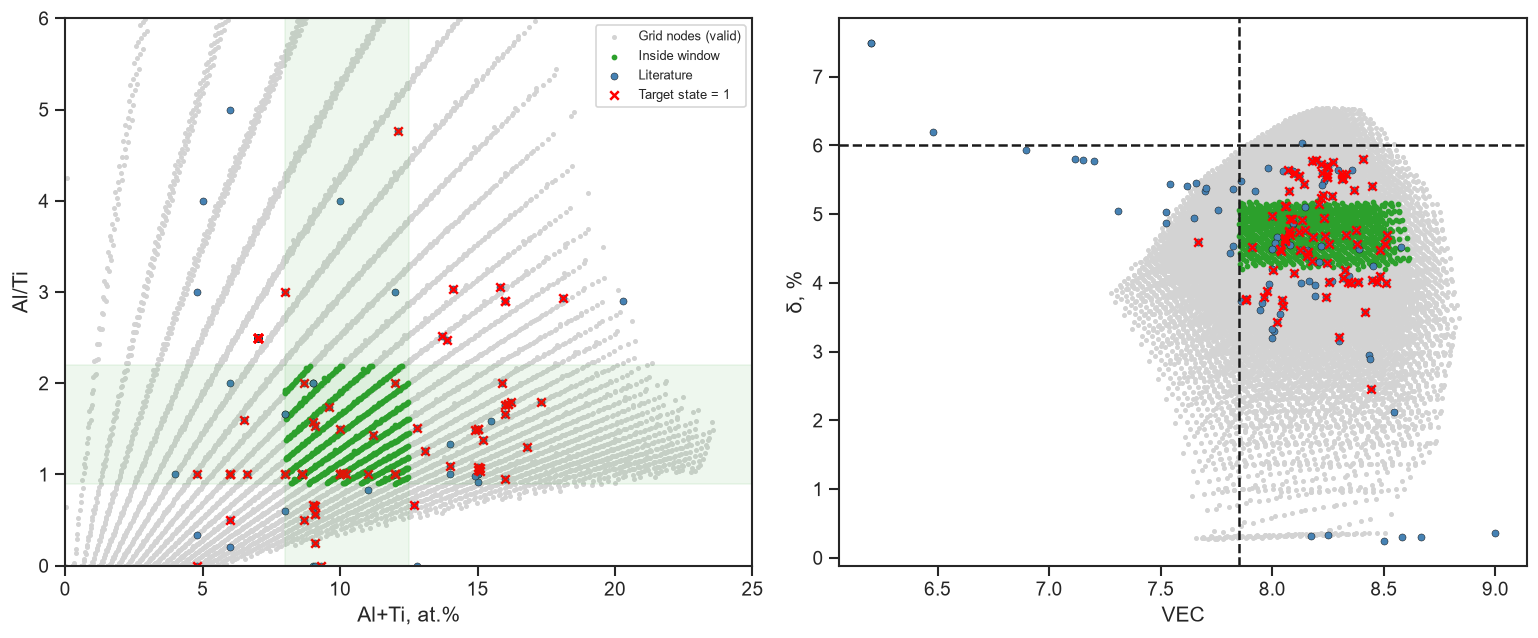

In [8]:
import matplotlib.pyplot as plt
import numpy as np

def fail_flags(d):
    return pd.DataFrame({
        'Al+Ti': ~d['Al_plus_Ti'].between(8.0, 12.5),
        'Al/Ti': ~d['Al_to_Ti_ratio'].between(0.9, 2.2),
        'VEC':   ~(d['VEC'] >= 7.85),
        'delta': ~(d['delta_atomic_radius'] <= 6.0)}, index=d.index)

fails = fail_flags(df_valid)
stats = pd.DataFrame({
    'removed by criterion': fails.sum(),
    'removed ONLY by it':   fails[fails.sum(axis=1) == 1].sum()})
stats['share of valid, %'] = (stats['removed by criterion'] / len(df_valid) * 100).round(1)
print(stats)
print("Passed all:", len(valid_l12), "of", len(df_valid))
stats.to_excel(TABLES_DIR / "window_filter_effect.xlsx")

lit = df_comp.copy()
lit = pd.concat([lit, calculate_descriptors(lit.assign(**{c: lit[c] for c in BASE_6}))
                 [['VEC', 'delta_atomic_radius']]], axis=1)
tgt = lit['Target state'] == 1

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))

a = ax[0]
a.scatter(df_valid['Al_plus_Ti'], df_valid['Al_to_Ti_ratio'], s=4, c='lightgray', label='Grid nodes (valid)')
a.scatter(valid_l12['Al_plus_Ti'], valid_l12['Al_to_Ti_ratio'], s=6, c='tab:green', label='Inside window')
a.scatter(df_comp['Al_plus_Ti'], df_comp['Al_to_Ti_ratio'], s=18, c='steelblue', edgecolor='k', lw=0.3, label='Literature')
a.scatter(df_comp.loc[tgt, 'Al_plus_Ti'], df_comp.loc[tgt, 'Al_to_Ti_ratio'], s=26, c='red', marker='x', label='Target state = 1')
a.axvspan(8.0, 12.5, color='tab:green', alpha=0.08)
a.axhspan(0.9, 2.2, color='tab:green', alpha=0.08)
a.set(xlim=(0, 25), ylim=(0, 6), xlabel='Al+Ti, at.%', ylabel='Al/Ti')
a.legend(fontsize=8)

b = ax[1]
b.scatter(df_valid['VEC'], df_valid['delta_atomic_radius'], s=4, c='lightgray')
b.scatter(valid_l12['VEC'], valid_l12['delta_atomic_radius'], s=6, c='tab:green')
b.scatter(lit['VEC'], lit['delta_atomic_radius'], s=18, c='steelblue', edgecolor='k', lw=0.3)
b.scatter(lit.loc[tgt, 'VEC'], lit.loc[tgt, 'delta_atomic_radius'], s=26, c='red', marker='x')
b.axvline(7.85, c='k', ls='--'); b.axhline(6.0, c='k', ls='--')
b.set(xlabel='VEC', ylabel='δ, %')

fig.tight_layout()
fig.savefig(FIGURES_DIR / "window_filter_effect.png", dpi=200)